# Ready-made model or your own? Five products decide

**A model someone else trained, used as it comes, scores 81 out of 100 on generated series where ours score 62, 65 and 42. On the backtest its average error is 22% worse than our winner's, although it is ahead on 61 of the 114 products. Five products carry nine tenths of the gap, and what went wrong on them can be reproduced, measured and guarded against.**

A supplier forecasts next year's monthly patient numbers for 114 medical products. [The example before this one](best-of-fifty.ipynb) tried fifty settings of small forecasters on that job. This one adds a candidate of another kind: a large model that was trained in advance on a great many other series and forecasts ours without learning anything from them first. One average on one backtest says to keep ours. TimeGym runs the ready-made model on the same cases as ours, with the same checks and the same scorecard, and keeps every product's score. That is what it takes to see what is behind the average.

*Data: monthly patient counts for medical products, 2000 to 2006, from the Monash Time Series Forecasting Archive, CC BY 4.0 ([source and license](data/README.md#hospital-patients)). The ready-made model is Chronos-2, published by Amazon under the Apache 2.0 license; its forecasts were made once and are saved next to this notebook ([what is saved](forecasts/README.md)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.neighbors import KNeighborsRegressor

from timegym import NaiveForecaster, Pipeline, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

RUN_MODEL = False  # True asks the model for every forecast: see "The ready-made model" below

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The job, and our forecasters

Seven years of monthly counts for each product, and a forecast for the year ahead. As in the previous example, the choice is made on the forecast of year 6, from years 1 to 5.

Ours are the three forecasters that example ended with. Its backtest could not tell them apart:

- **Smoothing**: a running average that gives the newest month a weight of 0.2 and forecasts a flat line. It was the winner of the fifty.
- **Neighbors**: find the 10 stretches of history most like the last 12 months and average what came next.
- **Same month last year.**

The score is the scaled error: the average miss divided by the product's usual month-to-month change, so that a product with 3,000 patients a month counts as much as one with 100. Lower is better.

In [2]:
patients = load("hospital-patients").astype(float)
months = patients.index.to_timestamp()
values, names = patients.to_numpy(), list(patients.columns)


class Smoothing:
    def __init__(self, alpha):
        self.alpha = alpha

    def fit(self, history):
        series = np.asarray(history, dtype=float).ravel()
        level = series[0]
        for value in series[1:]:
            level = self.alpha * value + (1 - self.alpha) * level
        self.level_ = level
        return self

    def predict(self, dates):
        return np.full(len(dates), self.level_)


def year_ahead(first_month):
    # One case per product: forecast 12 months from all the months before `first_month`.
    return [case for product in patients.columns
            for case in cases_from_series(patients[[product]], origins=[first_month], horizon=12, name=product)]


ours = {"Smoothing": Pipeline(Smoothing(0.2)),
        "Neighbors": Pipeline(KNeighborsRegressor(10), window_length=12),
        "Same month last year": Pipeline(NaiveForecaster(strategy="seasonal", period=12))}
print(f"{patients.shape[1]} products, {len(patients)} months, {months[0]:%B %Y} to {months[-1]:%B %Y}.")

114 products, 84 months, January 2000 to December 2006.


## The ready-made model

[Chronos-2](https://huggingface.co/amazon/chronos-2) is a neural network with 120 million parameters. Amazon trained it on a large collection of other series, real and generated, and published it under the Apache 2.0 license. Hand it a history and it returns a range for each coming month; we take the middle of the range as the forecast. It is used as it comes: nothing in it is fitted to our products.

To TimeGym it is one more forecaster, a class with `fit` and `predict`. `fit` keeps the history and `predict` asks the model.

Running the model takes PyTorch and a download of 478 MB, which is a lot for an example. So the class files every answer under a fingerprint of the history it was given, and this notebook reads the answers the model gave when the example was built: about 900 forecasts in a file of 100 KB ([what is saved](forecasts/README.md)). Set `RUN_MODEL = True` in the first cell and the notebook asks the model for every forecast instead. That needs `pip install chronos-forecasting`, and about 40 milliseconds a forecast on four processor cores, a minute or two in all. A history with no saved forecast raises an error. Nothing is filled in.

**Has the model seen our data?** A model trained on public series may have been trained on the very ones we test it on, and then a backtest measures its memory. The makers list this dataset, under the name Hospital, among 27 that they kept out of training in order to test on them ([Ansari et al. 2024](https://arxiv.org/abs/2403.07815)), and say that none of the 27 was in the training data of Chronos-2 ([Ansari et al. 2025](https://arxiv.org/abs/2510.15821)). We take their word for it: nothing in this notebook can check it.

In [3]:
MODEL, REVISION = "amazon/chronos-2", "29ec3766d36d6f73f0696f85560a422f50e8498c"
SAVED = Path("forecasts")


def fingerprint(history):
    # A short name for a history: the same numbers always give the same name.
    return hashlib.sha1((np.round(history, 4) + 0.0).tobytes()).hexdigest()[:12]


forecasts = {}   # fingerprint of a history -> the model's forecast for the 12 months after it
if not RUN_MODEL:
    saved = pd.read_csv(SAVED / "ready-made-model.csv", index_col="history")
    forecasts = {key: row.to_numpy() for key, row in saved.iterrows()}


class ReadyMade:
    model = None   # loaded once, the first time a forecast is asked for

    def __init__(self, months=None):
        self.months = months   # None hands the model the whole history

    def fit(self, history):
        series = np.asarray(history, dtype=float).ravel()
        self.history_ = series if self.months is None else series[-self.months:]
        return self

    def predict(self, dates):
        key = fingerprint(self.history_)
        if key not in forecasts:
            forecasts[key] = self.ask(len(dates))
        return forecasts[key]

    def ask(self, steps):
        if not RUN_MODEL:
            raise KeyError("No saved forecast for this history. Set RUN_MODEL = True to ask the model.")
        if ReadyMade.model is None:
            from chronos import Chronos2Pipeline
            ReadyMade.model = Chronos2Pipeline.from_pretrained(MODEL, revision=REVISION, device_map="cpu")
        middle, _ = ReadyMade.model.predict_quantiles(
            [self.history_], prediction_length=steps, quantile_levels=[0.5])
        return np.asarray(middle[0], dtype=float).ravel()


ready_made = Pipeline(ReadyMade())
print("Asking the model." if RUN_MODEL else f"{len(forecasts)} saved forecasts.")

904 saved forecasts.


## What each one can do

Before the real data, the scorecard. It runs a forecaster on generated series of ten patterns with the shape of our job, five years of history and one year ahead, and gives a score out of 100 for how close it comes to the best forecast anyone could make. That forecast is known, because we generated the series.

The model's scorecard was made once and saved with `save_baseline`. Ours are computed here, on the same series. `compare` then counts the cells of the scorecard, ten patterns at two noise levels, where one of ours is further from the best possible forecast than the model by more than chance would explain. For that, each cell is scored on 30 series. The previous example used the default of 10, and some of its rows differ from the ones here by ten points or more.

In [4]:
shape = dict(context_length=60, horizon=12, instances=30)   # 30 series a cell: what `compare` asks for
CARD = SAVED / "ready-made-scorecard.json"
if RUN_MODEL:
    ready_made.scorecard(title="Chronos-2", **shape).save_baseline(CARD)
    forecasts.clear()   # the scorecard's 600 series are kept as a scorecard, not as forecasts
ready_card = json.loads(CARD.read_text(encoding="utf-8"))
cards = {name: pipeline.scorecard(**shape) for name, pipeline in ours.items()}

titles = cards["Smoothing"].table.drop_duplicates("pattern").set_index("pattern")["title"]
rows = pd.DataFrame({
    "Ready-made": pd.DataFrame(ready_card["cells"]).groupby("pattern", sort=False)["score"].mean().rename(titles),
    **{name: card.table.groupby("title", sort=False)["score"].mean() for name, card in cards.items()}})
rows.loc["Whole scorecard"] = rows.mean()
display(rows.round(0).astype(int).rename_axis("Pattern (score out of 100)"))

behind = {name: len(card.compare(CARD).worse) for name, card in cards.items()}
print("Cells, of 20, where it is further from the best possible forecast")
print("than the ready-made model, by more than chance:")
print("  " + ", ".join(f"{name.lower()} {count}" for name, count in behind.items()) + ".")

whole, shift = rows.loc["Whole scorecard"], rows.loc["Sudden level shift"]
assert all(abs(whole[name] - cards[name].score) < 1e-6 for name in ours)
assert np.allclose(whole, [81, 62, 65, 42], atol=1.5)
assert rows["Ready-made"].min() > 55 and (rows[list(ours)].min() < 40).all()
assert np.allclose(rows.loc["Straight-line trend"], [80, 43, 39, 29], atol=2.5)
assert np.allclose(rows.loc["Trend + seasonal cycle"], [75, 18, 25, 29], atol=2.5)
assert np.allclose(shift[["Ready-made", "Smoothing", "Neighbors"]], [76, 87, 82], atol=2.5)
assert rows.loc["Random walk: shocks never fade", "Smoothing"] > rows.loc["Random walk: shocks never fade", "Ready-made"] + 4
assert rows.loc["Irregular cycles (AR(2))", "Neighbors"] > rows.loc["Irregular cycles (AR(2))", "Ready-made"] + 2
assert 11 <= behind["Smoothing"] <= 15 and 7 <= behind["Neighbors"] <= 11 and behind["Same month last year"] >= 18

,Ready-made,Smoothing,Neighbors,Same month last year
Pattern (score out of 100),,,,
Pure noise,94,87,91,49
Noise around a fixed level,94,87,91,49
Straight-line trend,80,43,39,29
Repeating seasonal cycle,82,21,73,49
Trend + seasonal cycle,75,18,25,29
Sudden level shift,76,87,82,51
Mean reversion (AR(1)): shocks fade,80,78,76,43
Irregular cycles (AR(2)),58,34,63,25
Random walk: shocks never fade,85,92,60,55


Cells, of 20, where it is further from the best possible forecast
than the ready-made model, by more than chance:
  smoothing 13, neighbors 9, same month last year 20.


The ready-made model can do things ours cannot. It follows a straight-line trend (80, where ours score 43, 39 and 29) and a trend with a season on top (75 against 18, 25 and 29). Its lowest row is 58; each of ours has a row below 40. Smoothing is further from the best forecast than the model in 13 of the 20 cells, neighbors in 9, and same month last year in all 20.

One of ours scores higher in three rows. Smoothing does on a random walk (92 against 85). Neighbors does on irregular cycles (63 against 58). And both do on a sudden level shift: 87 and 82 against 76. Keep that last row in mind.

By this table the choice looks easy.

## The backtest year

Now the products. All four forecast year 6 from years 1 to 5: 114 cases, the same for every forecaster. `assert_passed` stops the notebook if a forecast crashed, failed an output check or had no saved answer.

In [5]:
def backtest(pipelines, first_month):
    # Every forecaster on the same cases: one row per product, one column per forecaster.
    cases = year_ahead(first_month)
    scores, made = {}, {}
    for name, pipeline in pipelines.items():
        run = pipeline.run(cases=cases)
        run.report.assert_passed()
        scores[name] = [entry.result.metrics["mase"] for entry in run.cases]
        made[name] = np.array([np.ravel(entry.forecast.point) for entry in run.cases])
    return pd.DataFrame(scores, index=patients.columns), made


def difference(first, second):
    # The average of `first` minus `second` over the products, with a 95% interval.
    return paired_t_interval((first - second).to_numpy())


def as_text(interval):
    return f"{interval['mean']:+.3f} ({interval['ci95'][0]:+.3f} to {interval['ci95'][1]:+.3f})"


errors, made = backtest({"Ready-made": ready_made, **ours}, 60)   # year 6 from years 1 to 5
summary = pd.DataFrame({"Average scaled error": errors.mean(), "Middle product": errors.median()})
display(summary.round(3).rename_axis("Forecaster"))

ahead = {rival: int((errors["Ready-made"] < errors[rival]).sum()) for rival in ours}
print(f"Products, of {len(errors)}, where the ready-made model has the lower error than")
print("  " + ", ".join(f"{rival.lower()} {count}" for rival, count in ahead.items()) + ".")
print("Ready-made model's scaled error minus each of ours, with a 95% interval:")
for rival in ours:
    print(f"  {rival}: {as_text(difference(errors['Ready-made'], errors[rival]))}")

average = errors.mean()
assert np.allclose(average, [1.095, 0.895, 0.912, 0.919], atol=0.002)
assert np.allclose(errors.median(), [0.849, 0.826, 0.838, 0.842], atol=0.002)
assert abs(average["Ready-made"] / average["Smoothing"] - 1.22) < 0.01 and list(ahead.values()) == [61, 56, 62]
assert difference(errors["Ready-made"], errors["Smoothing"])["ci95"][0] > 0
assert difference(errors["Ready-made"], errors["Neighbors"])["ci95"][0] > 0
assert difference(errors["Ready-made"], errors["Same month last year"])["ci95"][0] < 0

,Average scaled error,Middle product
Forecaster,,
Ready-made,1.095,0.849
Smoothing,0.895,0.826
Neighbors,0.912,0.838
Same month last year,0.919,0.842


Products, of 114, where the ready-made model has the lower error than
  smoothing 61, neighbors 56, same month last year 62.
Ready-made model's scaled error minus each of ours, with a 95% interval:
  Smoothing: +0.200 (+0.009 to +0.391)
  Neighbors: +0.182 (+0.005 to +0.360)
  Same month last year: +0.176 (-0.012 to +0.364)


All 456 forecasts came back clean. By the average, the ready-made model is last, and not by a little: 1.095 against 0.895 for smoothing, which is 22% worse. Against smoothing and against neighbors the interval stays above zero, if only just.

The other numbers do not agree with the average. The middle product's error is about the same for all four, 0.83 to 0.85. And the ready-made model has the lower error on about half of the products against each of ours: 61, 56 and 62 of 114. An average that far from the middle is the work of a few products.

## Five products

Every product's score is in the table, so we can line the products up: the ready-made model's error minus smoothing's, from the product where the model is furthest ahead to the one where it is furthest behind.

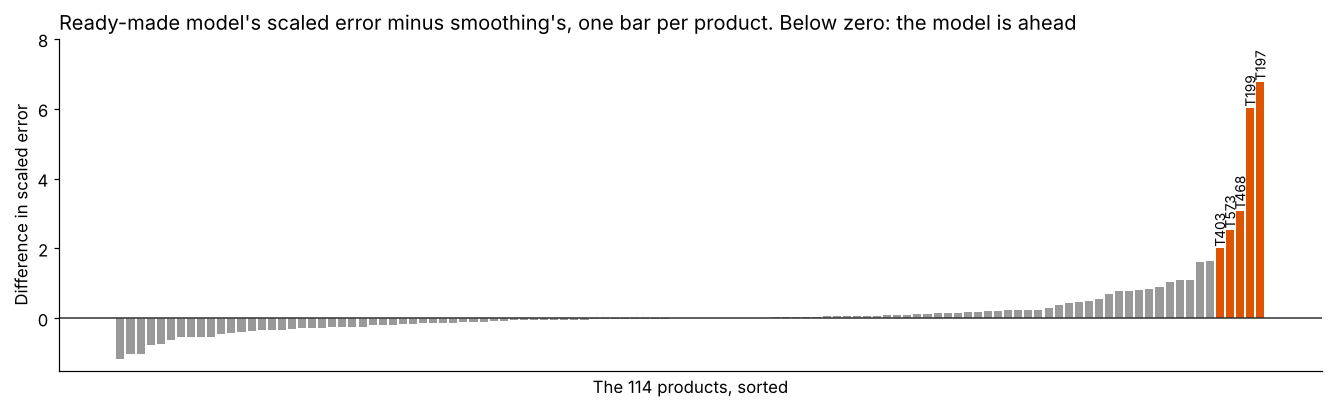

Five products carry 90% of the gap: T197, T199, T468, T573, T403.
On the other 109 products, ready-made minus smoothing is
  +0.022 (-0.064 to +0.108).


In [6]:
gap = (errors["Ready-made"] - errors["Smoothing"]).sort_values()
five = list(gap.index[::-1][:5])
share = gap[five].sum() / gap.sum()
others = paired_t_interval(gap.drop(five).to_numpy())

fig, ax = plt.subplots(figsize=(12, 3.6), layout="constrained")
ax.bar(range(len(gap)), gap, width=0.8, color=["#DD5500" if product in five else "0.6" for product in gap.index])
ax.axhline(0, color="0.2", linewidth=1)
for product in five:
    ax.annotate(product, (gap.index.get_loc(product), gap[product]), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=9, rotation=90)
ax.set(title="Ready-made model's scaled error minus smoothing's, one bar per product. Below zero: the model is ahead",
       xlabel="The 114 products, sorted", ylabel="Difference in scaled error", xticks=[], ylim=(-1.5, 8))
plt.show()
print(f"Five products carry {100 * share:.0f}% of the gap: {', '.join(five)}.")
print(f"On the other {len(gap) - 5} products, ready-made minus smoothing is")
print(f"  {as_text(others)}.")
assert five == ["T197", "T199", "T468", "T573", "T403"] and 0.87 < share < 0.92
assert abs(others["mean"] - 0.022) < 0.003 and others["ci95"][0] < 0 < others["ci95"][1]

Five products carry nine tenths of the gap. On the other 109 the two forecasters are level: the difference is 0.022, with an interval from about minus 0.06 to plus 0.11. Taking out a forecaster's five worst products flatters it, so this is no verdict. It only says that nothing else stands out.

What happened on those five? The table gives each product's average level in the five years of history, the level the model's forecast puts year 6 at, and the level that came.

,Year 1,Year 2,Year 3,Year 4,Year 5,Model's forecast,Year 6
Patients per month,,,,,,,
T197,443,893,911,477,467,896,461
T199,2478,4320,4449,2418,2529,3999,2488
T468,2502,3714,3703,2444,2637,3240,2476
T573,221,114,125,233,208,138,209
T403,306,237,306,334,329,248,349


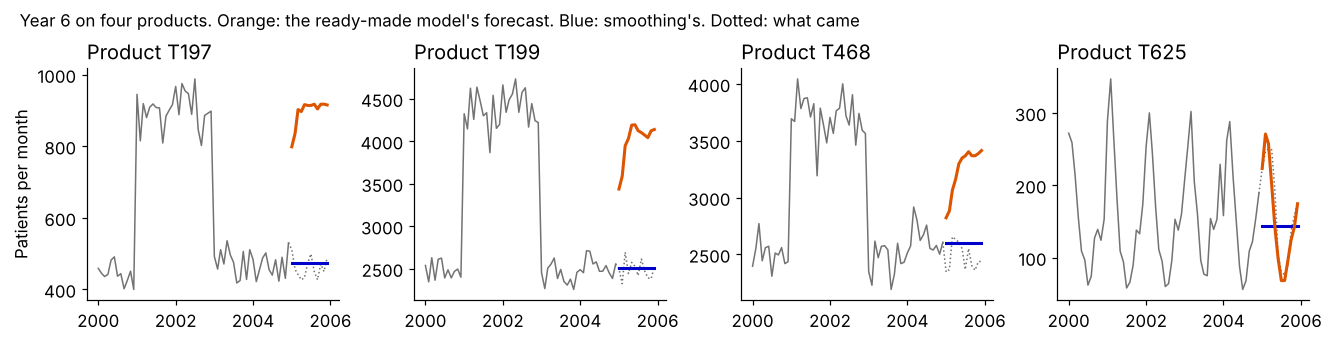

Product T625, scaled error: ready-made 0.37, smoothing 1.39.


In [7]:
levels = pd.DataFrame({f"Year {year + 1}": values[12 * year:12 * year + 12].mean(axis=0) for year in range(5)},
                      index=names)
levels["Model's forecast"] = made["Ready-made"].mean(axis=1)
levels["Year 6"] = values[60:72].mean(axis=0)
display(levels.loc[five].round(0).astype(int).rename_axis("Patients per month"))

fig, axes = plt.subplots(1, 4, figsize=(12, 3), layout="constrained")
for ax, product in zip(axes, ["T197", "T199", "T468", "T625"]):
    place = names.index(product)
    ax.plot(months[:60], values[:60, place], color="0.45", linewidth=1)
    ax.plot(months[59:72], values[59:72, place], color="0.45", linewidth=1, linestyle=":")
    ax.plot(months[60:72], made["Smoothing"][place], color="#0000CC", linewidth=2)
    ax.plot(months[60:72], made["Ready-made"][place], color="#DD5500", linewidth=2)
    ax.set_title(f"Product {product}")
    ax.set_xticks(months[::24], [f"{month:%Y}" for month in months[::24]])
axes[0].set_ylabel("Patients per month")
fig.suptitle("Year 6 on four products. Orange: the ready-made model's forecast. Blue: smoothing's. Dotted: what came",
             x=0.01, ha="left", fontsize=11)
plt.show()
print(f"Product T625, scaled error: ready-made {errors.loc['T625', 'Ready-made']:.2f},"
      f" smoothing {errors.loc['T625', 'Smoothing']:.2f}.")

shown = levels.loc[["T197", "T199", "T468"]]
assert np.allclose(levels.loc["T197"], [443, 893, 911, 477, 467, 896, 461], atol=3)
assert (shown["Model's forecast"] > 1.2 * shown["Year 5"]).all() and (shown["Year 6"] < 1.1 * shown["Year 5"]).all()
assert levels.loc["T573", "Model's forecast"] < 0.7 * levels.loc["T573", "Year 5"]
assert abs(levels.loc["T403", "Model's forecast"] - levels.loc["T403", "Year 2"]) < 15
assert errors.loc["T625", "Ready-made"] < 0.4 and errors.loc["T625", "Smoothing"] > 1.3

Three of the five have the same history. T197 ran at about 440 patients a month, then at about 900 for two years, and has been back near 470 for two years. The ready-made model forecasts 896 for year 6. What came was 461. T199 and T468 have the same shape and get the same kind of forecast. T573 is the mirror image: two low years, two years back up, and a forecast that drops again. T403 had one low year, and its forecast goes back to it.

In each case the model leaves the level of the last two years for one the product had before.

The fourth panel is the reason to want this model. T625 has a season; the model follows it, and smoothing's flat line cannot.

## The same error on generated series

The row to keep in mind was the sudden level shift. These products are a special kind: the level moved and came back. Are the forecasts above what this model does with such a history, or are they five accidents? Five real products cannot say. Generated series can, because we can make as many as we like and we know the right forecast.

Take a level of 100, raise it to 200 for two years, bring it back to 100, and add noise. The best forecast for the coming year is 100, whatever came before. We cut one case from each of 20 such series and measure how much of the old height is in the model's forecast: 0 means the forecast stays at 100, and 1 means it goes all the way back to 200.

Two things vary: how long the series ran at 100 before the rise (one year, like our products, or three), and how long it has been back at 100 when we ask.

Months since the level came back,12,18,24,30,36
One year at 100 before the rise,0.02,0.10,0.44,0.13,0.08
Three years at 100 before the rise,0.01,0.01,0.01,0.12,0.08


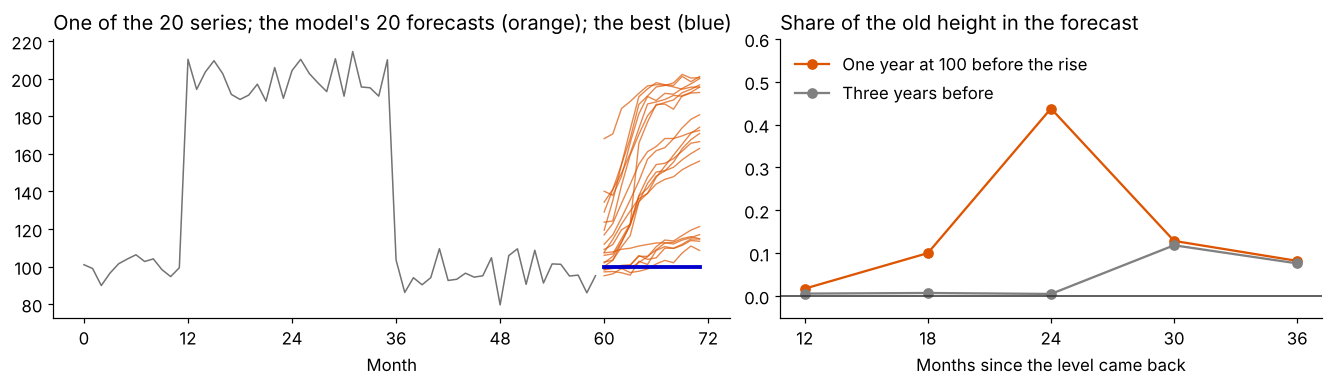

One year, two years high, two years back: 0.44 of the old height
  on average, and more than a quarter of it in 14 of 20 series.
  In the last month, 14 of the 20 forecasts are above 150.
One year, one year high, one year back: 0.78,
  and more than a quarter in 20 of 20 series.
Ours on the first of these:
  smoothing 0.01, neighbors 0.07, same month last year 0.00.


In [8]:
def came_and_went(before, high, since, series=20, seed=0):
    # `before` months at 100, `high` months at 200, then back at 100: `since` months of history
    # and the 12 months to forecast. One column per series.
    rng = np.random.default_rng(seed)
    level = np.r_[np.full(before, 100.0), np.full(high, 200.0), np.full(since + 12, 100.0)]
    index = pd.period_range("2000-01", periods=len(level), freq="M")
    return pd.DataFrame(level[:, None] + rng.normal(0, 8, (len(level), series)), index=index).rename(columns=str)


def old_height(pipeline, before, high, since):
    # The share of the old height in each series' forecast for the coming year.
    table = came_and_went(before, high, since)
    cases = [case for name in table
             for case in cases_from_series(table[[name]], origins=[len(table) - 12], horizon=12, name=name)]
    run = pipeline.run(cases=cases)
    run.report.assert_passed()
    return np.array([(np.mean(entry.forecast.point) - 100) / 100 for entry in run.cases])


asked = [12, 18, 24, 30, 36]
shares = {before: [old_height(ready_made, before, 24, since) for since in asked] for before in (12, 36)}
grid = pd.DataFrame({"One year at 100 before the rise": [share.mean() for share in shares[12]],
                     "Three years at 100 before the rise": [share.mean() for share in shares[36]]}, index=asked).T
display(grid.round(2).rename_axis("Months since the level came back", axis=1))

example = came_and_went(12, 24, 24).to_numpy()   # one year, two years high, two years back
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.4), layout="constrained", width_ratios=[1.25, 1])
left.plot(range(60), example[:60, 0], color="0.45", linewidth=1)
paths = np.array([ReadyMade().fit(series[:60]).predict(range(12)) for series in example.T])
left.plot(range(60, 72), paths.T, color="#DD5500", linewidth=0.9, alpha=0.7)
left.plot(range(60, 72), np.full(12, 100.0), color="#0000CC", linewidth=2.5)
left.set(title="One of the 20 series; the model's 20 forecasts (orange); the best (blue)", xlabel="Month",
         xticks=range(0, 73, 12))
right.plot(asked, grid.iloc[0], color="#DD5500", marker="o", label="One year at 100 before the rise")
right.plot(asked, grid.iloc[1], color="0.5", marker="o", label="Three years before")
right.axhline(0, color="0.2", linewidth=1)
right.set(title="Share of the old height in the forecast", xlabel="Months since the level came back", xticks=asked,
          ylim=(-0.05, 0.6))
right.legend(loc="upper left")
plt.show()

two_years, equal = shares[12][2], old_height(ready_made, 12, 12, 12)
flat = {name: old_height(pipeline, 12, 24, 24).mean() for name, pipeline in ours.items()}
print(f"One year, two years high, two years back: {two_years.mean():.2f} of the old height")
print(f"  on average, and more than a quarter of it in {(two_years > 0.25).sum()} of {len(two_years)} series.")
print(f"  In the last month, {(paths[:, -1] > 150).sum()} of the {len(paths)} forecasts are above 150.")
print(f"One year, one year high, one year back: {equal.mean():.2f},")
print(f"  and more than a quarter in {(equal > 0.25).sum()} of {len(equal)} series.")
print("Ours on the first of these:")
print("  " + ", ".join(f"{name.lower()} {round(share, 2) + 0.0:.2f}" for name, share in flat.items()) + ".")
assert np.allclose(grid.iloc[0], [0.02, 0.10, 0.44, 0.13, 0.08], atol=0.02)
assert np.allclose(grid.iloc[1], [0.01, 0.01, 0.01, 0.12, 0.08], atol=0.02)
assert (two_years > 0.25).sum() == 14 and abs(equal.mean() - 0.78) < 0.02 and (equal > 0.25).all()
assert (paths[:, -1] > 150).sum() == 14
assert max(abs(share) for share in flat.values()) < 0.08

It is not five accidents. With one year before the rise and two years since the level came back, which is the history of our products, the model's forecast carries 44% of the old height on average, and more than a quarter of it in 14 of the 20 series. The average understates what happens to a single forecast: the forecasts climb through the year, and in its last month 14 of the 20 are above 150. Our three forecasters stay at the present level.

It is also narrow. Ask six months earlier or six months later and the share is 0.10 and 0.13. Give the series three years at 100 before the rise and it is 0.01. Make all three stretches one year long and it is 0.78, in every one of the 20 series.

So the error is not a general weakness with levels that move. It takes two things at once: a short stretch before the rise, and a time since the level came back that is about as long as the high stretch lasted. A low stretch, a high one and a low one of similar length may look to the model like a slow cycle that is due to turn. That is a guess; we cannot see inside the model. What the cases measure is when it happens. Three of our five products met both conditions in year 6, and T573 is their mirror image. The fifth, T403, does not fit: its low year was three years back, and these series do not explain its forecast.

## What to do about it

Because the model is a class, changing how it is used takes a few lines. Three changes one might try:

- **Less history.** The error needs the old level in view, so hand the model only the last 24 months.
- **A guard.** When the model's forecast puts the coming year more than 15% above or below the last 12 months, use smoothing for that product. And the same with a limit of 25%.
- **An average** of the model's forecast and one of ours, month by month.

And three years to try them on instead of one: year 5 forecast from years 1 to 4, year 6 as before, and year 7 from years 1 to 6.

In [9]:
class Guarded:
    def __init__(self, limit):
        self.limit = limit

    def fit(self, history):
        self.recent_ = float(np.asarray(history, dtype=float).ravel()[-12:].mean())
        self.model_, self.ours_ = ReadyMade().fit(history), Smoothing(0.2).fit(history)
        return self

    def predict(self, dates):
        forecast = self.model_.predict(dates)
        moved = abs(forecast.mean() / self.recent_ - 1)
        return self.ours_.predict(dates) if moved > self.limit else forecast


class LastYear:
    def fit(self, history):
        self.year_ = np.asarray(history, dtype=float).ravel()[-12:]
        return self

    def predict(self, dates):
        return self.year_


class AverageWith:
    def __init__(self, other):
        self.other = other

    def fit(self, history):
        self.model_, self.other_ = ReadyMade().fit(history), self.other.fit(history)
        return self

    def predict(self, dates):
        return (self.model_.predict(dates) + self.other_.predict(dates)) / 2


candidates = {"Ready-made": ready_made,
              "Ready-made on the last 24 months": Pipeline(ReadyMade(months=24)),
              "Ready-made, guarded at 15%": Pipeline(Guarded(0.15)),
              "Ready-made, guarded at 25%": Pipeline(Guarded(0.25)),
              "Average of ready-made and last year": Pipeline(AverageWith(LastYear())),
              "Average of ready-made and smoothing": Pipeline(AverageWith(Smoothing(0.2))),
              **ours}
years = {"Year 5": 48, "Year 6": 60, "Year 7": 72}
by_year, moves = {}, {}
for label, first in years.items():
    by_year[label], forecast = backtest(candidates, first)
    recent = values[first - 12:first].mean(axis=0)
    called = forecast["Ready-made"].mean(axis=1) / recent - 1   # the move in level the model calls for
    came = values[first:first + 12].mean(axis=0) / recent - 1    # the move that came
    large = abs(called) > 0.15
    moves[label] = {"called": int(large.sum()), "called at 25%": int((abs(called) > 0.25).sum()),
                    "called and came": int((large & (abs(came) > 0.15) & (called * came > 0)).sum()),
                    "came": int((abs(came) > 0.15).sum()),
                    "smoothing closer": int((by_year[label]["Ready-made"] > by_year[label]["Smoothing"])[large].sum())}

table = pd.DataFrame({label: scores.mean() for label, scores in by_year.items()})
display(table.round(3).rename_axis("Average scaled error"))
print("Scaled error minus smoothing's, with a 95% interval:")
for label, scores in by_year.items():
    print(label)
    for name in ("Ready-made", "Ready-made on the last 24 months", "Ready-made, guarded at 15%",
                 "Average of ready-made and last year"):
        print(f"  {name:<37}{as_text(difference(scores[name], scores['Smoothing']))}")

moves = pd.DataFrame(moves)
print("Level moves of more than 15%, by year:")
print(f"  the model called for {', '.join(map(str, moves.loc['called']))} (the guard's products);")
print(f"  of those, came, in the same direction: {', '.join(map(str, moves.loc['called and came']))};")
print(f"  smoothing was closer than the model on {', '.join(map(str, moves.loc['smoothing closer']))} of them;")
print(f"  moves of that size that came: {', '.join(map(str, moves.loc['came']))}.")
shorter = by_year["Year 5"]["Ready-made on the last 24 months"] > by_year["Year 5"]["Ready-made"]
print(f"Year 5: the last 24 months do worse than the whole history")
print(f"  on {shorter.sum()} of the {len(shorter)} products.")

assert np.allclose(table.loc["Ready-made"], [1.058, 1.095, 0.913], atol=0.002)
assert np.allclose(table.loc["Ready-made on the last 24 months"], [1.285, 0.853, 0.931], atol=0.002)
assert np.allclose(table.loc["Ready-made, guarded at 15%"], [1.045, 0.871, 0.913], atol=0.002)
assert np.allclose(table.loc["Ready-made, guarded at 25%"], [1.058, 0.936, 0.913], atol=0.002)
assert np.allclose(table.loc["Average of ready-made and last year"], [1.031, 0.902, 0.857], atol=0.002)
assert np.allclose(table.loc["Average of ready-made and smoothing"], [1.067, 0.924, 0.896], atol=0.002)
assert np.allclose(table.loc["Smoothing"], [1.125, 0.895, 0.975], atol=0.002)
assert list(moves.loc["called"]) == [1, 9, 0] and list(moves.loc["called at 25%"]) == [0, 5, 0]
assert list(moves.loc["called and came"]) == [0, 1, 0] and list(moves.loc["smoothing closer"]) == [1, 9, 0]
assert list(moves.loc["came"]) == [7, 3, 4] and shorter.sum() == 78
for label in ("Year 5", "Year 7"):   # as it comes, the model is ahead of each of ours
    assert table.loc["Ready-made", label] < table.loc[list(ours), label].min()
    assert difference(by_year[label]["Ready-made"], by_year[label]["Smoothing"])["ci95"][1] < 0
    assert table[label].idxmin() == "Average of ready-made and last year"
    assert abs(table.loc["Ready-made", label] / table.loc["Smoothing", label] - 0.94) < 0.005
for name in ("Ready-made, guarded at 15%", "Average of ready-made and last year"):   # level with smoothing in year 6
    low, high = difference(by_year["Year 6"][name], by_year["Year 6"]["Smoothing"])["ci95"]
    assert low < 0 < high
assert (table.loc["Ready-made, guarded at 15%"] <= table.loc["Ready-made"] + 1e-9).all()

,Year 5,Year 6,Year 7
Average scaled error,,,
Ready-made,1.058,1.095,0.913
Ready-made on the last 24 months,1.285,0.853,0.931
"Ready-made, guarded at 15%",1.045,0.871,0.913
"Ready-made, guarded at 25%",1.058,0.936,0.913
Average of ready-made and last year,1.031,0.902,0.857
Average of ready-made and smoothing,1.067,0.924,0.896
Smoothing,1.125,0.895,0.975
Neighbors,1.586,0.912,0.954
Same month last year,1.136,0.919,0.957


Scaled error minus smoothing's, with a 95% interval:
Year 5
  Ready-made                           -0.067 (-0.123 to -0.010)
  Ready-made on the last 24 months     +0.160 (+0.075 to +0.246)
  Ready-made, guarded at 15%           -0.080 (-0.129 to -0.030)
  Average of ready-made and last year  -0.094 (-0.139 to -0.050)
Year 6
  Ready-made                           +0.200 (+0.009 to +0.391)
  Ready-made on the last 24 months     -0.042 (-0.080 to -0.003)
  Ready-made, guarded at 15%           -0.024 (-0.092 to +0.044)
  Average of ready-made and last year  +0.007 (-0.094 to +0.108)
Year 7
  Ready-made                           -0.062 (-0.116 to -0.009)
  Ready-made on the last 24 months     -0.044 (-0.083 to -0.005)
  Ready-made, guarded at 15%           -0.062 (-0.116 to -0.009)
  Average of ready-made and last year  -0.118 (-0.164 to -0.071)
Level moves of more than 15%, by year:
  the model called for 1, 9, 0 (the guard's products);
  of those, came, in the same direction: 0, 1, 0;
  

**Less history** is the best row of year 6 (0.853) and the worst of the model's rows in year 5 (1.285), where it is worse than the whole history on 78 of the 114 products. It fixed the year we were looking at. Tested on that year alone, it would have gone into use.

**The guard** at 15% overrules the model on 1, 9 and 0 products in the three years and is never worse than the model alone: 1.045, 0.871 and 0.913. In year 6 that is level with smoothing. At 25% it overrules 5 of the 9 and scores 0.936. The limit matters, and we set it after seeing year 6.

Why can so crude a rule work? In the three years the model called for a move of more than 15% ten times. A move that large came, in the same direction, once, and smoothing was closer than the model on all ten. Moves that large did come, 14 times, and the model called one of them. On these products a large move in the model's forecast has marked the error, not something the model knew.

**The averages** need no limit. The one with same month last year scores 1.031, 0.902 and 0.857: the lowest of the table in years 5 and 7, and level with smoothing in year 6.

And the model as it comes? In years 5 and 7 it is ahead of all three of ours, by 6% over smoothing both times, with an interval that stays below zero. Keeping ours on the strength of year 6's average would have given that up.

So the model goes into use, with a guard or inside an average. The reason is not one average. We know what the model can do that ours cannot, which five products made the bad year, when that error happens, and what each fix does in the other years.

In [10]:
if RUN_MODEL:   # how the forecasts this notebook reads were written
    asked = pd.DataFrame.from_dict(forecasts, orient="index", columns=[str(month) for month in range(1, 13)])
    asked.rename_axis("history").sort_index().to_csv(SAVED / "ready-made-model.csv", float_format="%.6g",
                                                     lineterminator="\n")
    print(f"Saved {len(asked)} forecasts.")

## What TimeGym added

- A model of another kind came in as a class with `fit` and `predict`, and went through the same cases, the same output checks and the same scoring as ours. Its forecasts were made once and read back, and `assert_passed` made sure none was missing or malformed.
- A scorecard for a model too heavy to run every time: made once, saved with `save_baseline`, and `compare` put ours against it cell by cell.
- Every product's score kept, not only the average. "Ahead on 61 of 114" and the five products are a few lines on that table.
- Cases cut from generated series with a known right answer. The error could be reproduced at will, and its conditions measured.
- The same cases for every variant over three years, which is how the fix that only fixed one year showed itself.

## Change one thing

These run on the saved forecasts:

- Set the guard's limit to 0.20, or let it fall back on same month last year: `self.ours_` in `Guarded`.
- Weight the average two parts model to one part last year.
- Look at another product: `levels.loc["T162"]`, and `made["Ready-made"][names.index("T162")]` for its forecast.

These ask the model for forecasts it has not made, so they need `RUN_MODEL = True`:

- In `came_and_went`, change the height (`200.0`) or the noise (`8`).
- Hand the model 36 months: `ReadyMade(months=36)`.
- Ask the model for its range on T197: `ReadyMade.model.predict_quantiles([values[:60, names.index("T197")]], prediction_length=12, quantile_levels=[0.05, 0.95])`. Does the range hold both levels?

**What this doesn't show.** One supplier's products and three test years, and all three years were in view while the guard and the averages were chosen. None of these numbers is a test on a year nobody had looked at, and the guard's limit moves the result of year 6 from 0.871 to 0.936. The intervals treat the 114 products as independent; products of one supplier share good and bad years, so the true intervals are wider, if anything. This is one model at one revision, with forecasts made once on one machine. Another pretrained model, or the next version of this one, may not make this error, or may make others. The model can also give a range, take other series as inputs and be trained further on your own data; none of that was tried. That the dataset was kept out of the model's training is its makers' statement. The generated series have one height and one noise level, and the reading of the error as a slow cycle is a guess.

**Related:** [You tried 50 models: is the winner real?](best-of-fifty.ipynb) for the fifty settings ours came from, [A traffic jump: is this the new normal?](traffic-jump.ipynb) for another level that moved, [Compare with a saved baseline](../docs/api/scorecard.md#compare-with-a-saved-baseline) in the reference, and [Write and test a custom model](../tutorials/02_custom_model.ipynb) for the two methods a class needs. More examples are on the [examples page](../docs/examples.md).